# California Home Price Prediction
## Week 5: Model Comparison

This notebook checks why the Week 4 R² was unusually low, corrects clear target errors, and compares Linear Regression, Decision Tree, and Random Forest on the same April 2026 test set.

In [1]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "California"
RANDOM_STATE = 42

## 1. Load the data

Load the same 15 months used in earlier weeks. `ListPrice` is used only to check the target; it is not a model feature.

In [2]:
columns = [
    "ListingKey", "CloseDate", "ClosePrice", "ListPrice",
    "PropertyType", "PropertySubType", "LivingArea", "BedroomsTotal",
    "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt",
    "City", "CountyOrParish"
]

frames = []
for path in sorted(RAW_DIR.glob("CRMLSSold*.csv")):
    monthly = pd.read_csv(path, usecols=columns, low_memory=False)
    monthly["SourceMonth"] = int(path.stem[-6:])
    frames.append(monthly)

assert len(frames) == 15, f"Expected 15 monthly files, found {len(frames)}"
raw_df = pd.concat(frames, ignore_index=True)
df = raw_df[
    raw_df["PropertyType"].eq("Residential")
    & raw_df["PropertySubType"].eq("SingleFamilyResidence")
].copy()

print(f"Raw rows: {len(raw_df):,}")
print(f"Residential single-family rows: {len(df):,}")

Raw rows: 321,972
Residential single-family rows: 161,314


## 2. Check the Week 4 baseline

The pipeline and chronological split were correct. The main issue was target quality: several normal homes had close prices about 1,000 times their list prices. For example, a home listed near $825,000 was recorded as closing for $796 million.

Use a broad rule to remove only clear errors:

- close price must be at least $10,000;
- when list price is available, the close-to-list ratio must be between 0.2 and 5.

This rule still keeps genuine luxury sales and removes only a very small fraction of records.

In [3]:
numeric_columns = [
    "ClosePrice", "ListPrice", "LivingArea", "BedroomsTotal",
    "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

close_to_list = df["ClosePrice"] / df["ListPrice"]
bad_target = (
    df["ClosePrice"].isna()
    | (df["ClosePrice"] < 10_000)
    | ((df["ListPrice"] > 0) & ~close_to_list.between(0.2, 5))
)

examples = df.loc[bad_target].nlargest(8, "ClosePrice")[[
    "SourceMonth", "ClosePrice", "ListPrice", "LivingArea", "City"
]]
display(examples)
print(f"Clear target errors removed: {bad_target.sum():,} of {len(df):,} ({bad_target.mean() * 100:.3f}%)")

df = df.loc[~bad_target].copy()
df = df.sort_values(["CloseDate", "SourceMonth"]).drop_duplicates("ListingKey", keep="last")

,SourceMonth,ClosePrice,ListPrice,LivingArea,City
184349,202510,"989,500,000.000","979,000.000","2,289.000",Valencia
59688,202504,"970,000,000.000","974,777.000","1,976.000",Chula Vista
109210,202506,"900,000,000.000","15,500,000.000","11,000.000",Glennville
156141,202509,"875,000,000.000","875,000.000","1,730.000",San Diego
162818,202509,"835,800,000.000","835,800.000",718.000,Ramona
173423,202509,"815,000,000.000","809,000.000","1,900.000",Saugus
318321,202604,"796,000,000.000","824,900.000","1,936.000",Valley Center
317430,202604,"768,500,000.000","750,000.000","1,444.000",San Diego


Clear target errors removed: 115 of 161,314 (0.071%)


## 3. Finish cleaning and create the time split

Use the same features as Week 4. Keep April 2026 as the final test month and use April 2025 through March 2026 for training.

In [4]:
numeric_features = [
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
    "LotSizeSquareFeet", "YearBuilt"
]
categorical_features = ["City", "CountyOrParish"]
features = numeric_features + categorical_features
target = "ClosePrice"

invalid_rules = {
    "LivingArea": df["LivingArea"] <= 0,
    "BedroomsTotal": df["BedroomsTotal"] < 0,
    "BathroomsTotalInteger": df["BathroomsTotalInteger"] < 0,
    "LotSizeSquareFeet": df["LotSizeSquareFeet"] <= 0,
    "YearBuilt": (df["YearBuilt"] < 1800) | (df["YearBuilt"] > df["CloseDate"].dt.year),
}
for column, mask in invalid_rules.items():
    df.loc[mask.fillna(False), column] = np.nan
for column in categorical_features:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

development_train = df[df["SourceMonth"].between(202504, 202602)].copy()
validation = df[df["SourceMonth"] == 202603].copy()
train = df[df["SourceMonth"].between(202504, 202603)].copy()
test = df[df["SourceMonth"] == 202604].copy()

assert set(train["ListingKey"]).isdisjoint(set(test["ListingKey"]))
assert set(development_train["ListingKey"]).isdisjoint(set(validation["ListingKey"]))
assert set(validation["ListingKey"]).isdisjoint(set(test["ListingKey"]))
assert development_train["SourceMonth"].max() < validation["SourceMonth"].min()
assert validation["SourceMonth"].max() < test["SourceMonth"].min()
display(pd.DataFrame({
    "split": ["Development train", "Validation", "Final train", "Test"],
    "period": ["2025-04 to 2026-02", "2026-03", "2025-04 to 2026-03", "2026-04"],
    "rows": [len(development_train), len(validation), len(train), len(test)],
    "median_price": [development_train[target].median(), validation[target].median(),
                     train[target].median(), test[target].median()],
}))

,split,period,rows,median_price
0,Development train,2025-04 to 2026-02,118454,"885,000.000"
1,Validation,2026-03,11165,"898,000.000"
2,Final train,2025-04 to 2026-03,129619,"886,392.000"
3,Test,2026-04,12024,"920,875.000"


## 4. Build and validate the pipelines

Linear Regression uses scaling because its coefficients depend on feature size. Trees do not need scaling because they split values by order. March 2026 is used to choose a small set of tree settings; April remains untouched.

In [5]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

tree_preprocessor = make_preprocessor()
X_development = tree_preprocessor.fit_transform(development_train[features])
X_validation = tree_preprocessor.transform(validation[features])
y_development = development_train[target]
y_validation = validation[target]

decision_tree_candidates = [
    {"max_depth": 8, "min_samples_leaf": 20},
    {"max_depth": 14, "min_samples_leaf": 10},
    {"max_depth": 20, "min_samples_leaf": 5},
    {"max_depth": None, "min_samples_leaf": 5},
]
random_forest_candidates = [
    {"max_depth": 14, "min_samples_leaf": 5, "max_features": 0.7},
    {"max_depth": 20, "min_samples_leaf": 5, "max_features": 0.7},
    {"max_depth": 22, "min_samples_leaf": 3, "max_features": 0.7},
    {"max_depth": None, "min_samples_leaf": 3, "max_features": 0.7},
]

validation_rows = []
for params in decision_tree_candidates:
    candidate = DecisionTreeRegressor(random_state=RANDOM_STATE, **params)
    candidate.fit(X_development, y_development)
    predicted = candidate.predict(X_validation)
    validation_rows.append({"model": "Decision Tree",
                            "settings": f"depth={params['max_depth']}, leaf={params['min_samples_leaf']}",
                            **params,
                            "validation_r2": r2_score(y_validation, predicted)})

for params in random_forest_candidates:
    candidate = RandomForestRegressor(
        n_estimators=60, n_jobs=-1, random_state=RANDOM_STATE, **params
    )
    candidate.fit(X_development, y_development)
    predicted = candidate.predict(X_validation)
    validation_rows.append({"model": "Random Forest",
                            "settings": f"depth={params['max_depth']}, leaf={params['min_samples_leaf']}",
                            **params,
                            "validation_r2": r2_score(y_validation, predicted)})

validation_results = pd.DataFrame(validation_rows)
display(validation_results[["model", "settings", "validation_r2"]])

best_dt = (validation_results[validation_results["model"] == "Decision Tree"]
           .sort_values("validation_r2", ascending=False).iloc[0])
best_rf = (validation_results[validation_results["model"] == "Random Forest"]
           .sort_values("validation_r2", ascending=False).iloc[0])
print(f"Best Decision Tree validation R²: {best_dt['validation_r2']:.3f}")
print(f"Best Random Forest validation R²: {best_rf['validation_r2']:.3f}")

,model,settings,validation_r2
0,Decision Tree,"depth=8, leaf=20",0.512
1,Decision Tree,"depth=14, leaf=10",0.619
2,Decision Tree,"depth=20, leaf=5",0.645
3,Decision Tree,"depth=None, leaf=5",0.664
4,Random Forest,"depth=14, leaf=5",0.673
5,Random Forest,"depth=20, leaf=5",0.689
6,Random Forest,"depth=22, leaf=3",0.721
7,Random Forest,"depth=None, leaf=3",0.744


Best Decision Tree validation R²: 0.664
Best Random Forest validation R²: 0.744


## 5. Refit and compare on the final test

After choosing settings with March validation, refit all models on the complete April 2025–March 2026 training period. Evaluate April 2026 only once.

In [6]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", LinearRegression()),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeRegressor(
            max_depth=None if pd.isna(best_dt["max_depth"]) else int(best_dt["max_depth"]),
            min_samples_leaf=int(best_dt["min_samples_leaf"]),
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestRegressor(
            n_estimators=120,
            max_depth=None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
            min_samples_leaf=int(best_rf["min_samples_leaf"]),
            max_features=float(best_rf["max_features"]),
            n_jobs=-1, random_state=RANDOM_STATE,
        )),
    ]),
}

### Final results

R² is the required metric. MAE and RMSE are included to show the typical and large-error sizes.

In [7]:
results = []
predictions = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(train[features], train[target])
    predicted = model.predict(test[features])
    elapsed = time.perf_counter() - start
    predictions[name] = predicted

    results.append({
        "model": name,
        "test_r2": r2_score(test[target], predicted),
        "test_mae": mean_absolute_error(test[target], predicted),
        "test_rmse": mean_squared_error(test[target], predicted) ** 0.5,
        "training_seconds": elapsed,
    })

results = pd.DataFrame(results).sort_values("test_r2", ascending=False).reset_index(drop=True)
display(results)
print(f"Best model: {results.loc[0, 'model']}")

,model,test_r2,test_mae,test_rmse,training_seconds
0,Random Forest,0.691,"266,229.983","877,650.731",183.688
1,Linear Regression,0.623,"398,460.757","969,302.636",5.097
2,Decision Tree,0.526,"332,468.860","1,086,965.596",23.794


Best model: Random Forest


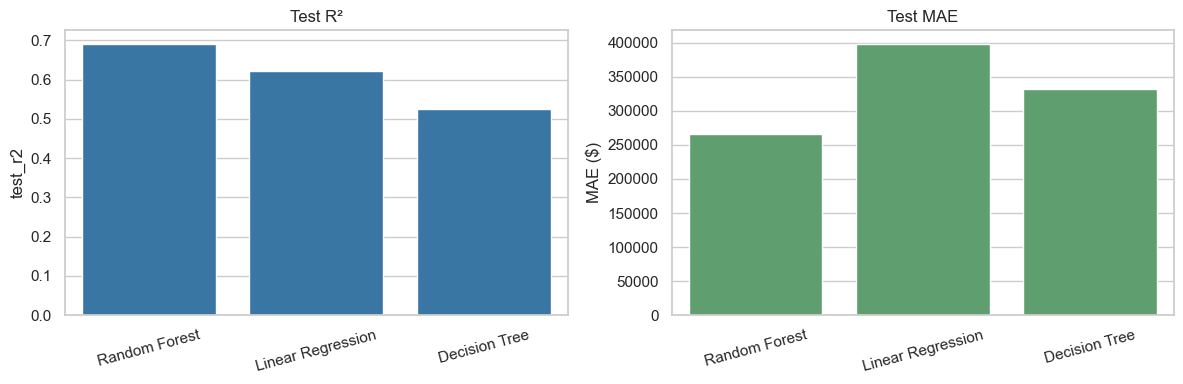

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=results, x="model", y="test_r2", ax=axes[0], color="#2878B5")
axes[0].set_title("Test R²")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=results, x="model", y="test_mae", ax=axes[1], color="#55A868")
axes[1].set_title("Test MAE")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE ($)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 6. Look at the best model

Plot a reproducible sample below the 99th price percentile so the main pattern is visible. All test rows are still included in the reported metrics.

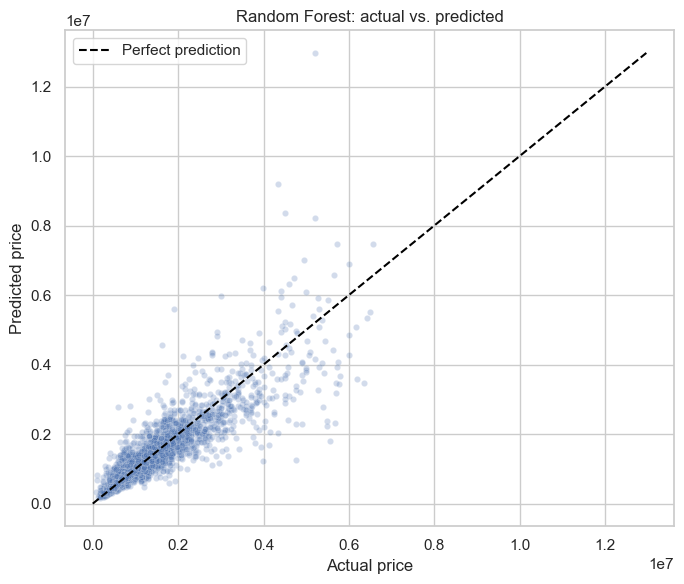

In [9]:
best_name = results.loc[0, "model"]
best_predictions = predictions[best_name]
plot_limit = test[target].quantile(0.99)
plot_data = pd.DataFrame({
    "Actual price": test[target].to_numpy(),
    "Predicted price": best_predictions,
})
plot_data = plot_data[plot_data["Actual price"] <= plot_limit]
plot_data = plot_data.sample(n=min(4000, len(plot_data)), random_state=RANDOM_STATE)

plt.figure(figsize=(7, 6))
sns.scatterplot(data=plot_data, x="Actual price", y="Predicted price", alpha=0.25, s=20)
line_max = max(plot_data[["Actual price", "Predicted price"]].max())
plt.plot([0, line_max], [0, line_max], "--", color="black", label="Perfect prediction")
plt.title(f"{best_name}: actual vs. predicted")
plt.legend()
plt.tight_layout()
plt.show()

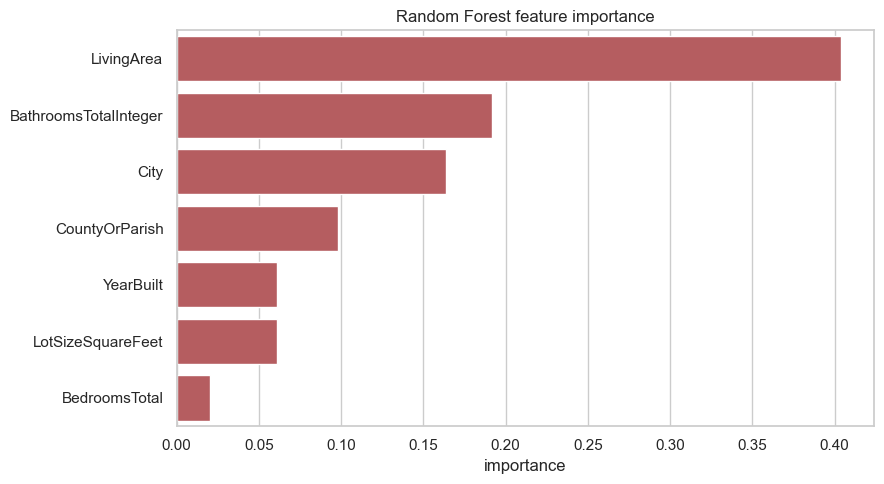

,feature,importance
4,LivingArea,0.404
0,BathroomsTotalInteger,0.192
2,City,0.164
3,CountyOrParish,0.098
6,YearBuilt,0.061
5,LotSizeSquareFeet,0.061
1,BedroomsTotal,0.020


In [10]:
forest_pipeline = models["Random Forest"]
feature_names = forest_pipeline.named_steps["preprocessor"].get_feature_names_out()
encoded_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": forest_pipeline.named_steps["model"].feature_importances_,
})

def original_feature(encoded_name):
    if encoded_name.startswith("numeric__"):
        return encoded_name.replace("numeric__", "")
    if encoded_name.startswith("categorical__City_"):
        return "City"
    return "CountyOrParish"

encoded_importance["feature"] = encoded_importance["feature"].map(original_feature)
importance = (encoded_importance.groupby("feature", as_index=False)["importance"]
              .sum().sort_values("importance", ascending=False))

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="importance", y="feature", color="#C44E52")
plt.title("Random Forest feature importance")
plt.ylabel("")
plt.tight_layout()
plt.show()
display(importance)

## Conclusion

- The old R² was mainly caused by a small number of incorrect close prices, not a broken pipeline.
- The target check removed only about 0.07% of residential single-family records.
- Corrected Linear Regression test R²: **0.623**.
- Decision Tree test R²: **0.526**; its lower test result shows that a single tree is unstable.
- Random Forest performed best with test R²: **0.691** and MAE of about **$266,230**.
- Linear Regression is fast and easy to explain, but it cannot capture many nonlinear relationships.
- A single Decision Tree is easy to visualize but is less stable and can overfit.
- Random Forest is more accurate and stable, but it takes longer and is less interpretable.

The next step is feature engineering, including property age, bed/bath ratios, and more detailed location information.